# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/preprocessed_data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/preprocessed_data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/preprocessed_data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/preprocessed_data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [112]:
avg_peak = pd.read_parquet('data/static_features/avg_and_peak.parquet')
entropy = pd.read_parquet('data/static_features/entropies.parquet')
total_min = pd.read_parquet('data/static_features/total_min.parquet')
total_min_det = pd.read_parquet('data/static_features/total_min_detailed.parquet')

In [84]:
df_eat = pd.read_parquet("data/preprocessed_data/df_eat.parquet")
df_act = pd.read_parquet("data/preprocessed_data/df_act.parquet")
df_eat["ID"] = df_eat.index
df_act["ID"] = df_act.index

In [122]:
entropy.index

MultiIndex([(    'act_entrX', 1600),
            (    'act_entrX', 1601),
            (    'act_entrX', 1602),
            (    'act_entrX', 1603),
            (    'act_entrX', 1604),
            (    'act_entrX', 1605),
            (    'act_entrX', 1606),
            (    'act_entrX', 1607),
            (    'act_entrX', 1608),
            (    'act_entrX', 1609),
            ...
            ('eat_entr_mean', 1641),
            ('eat_entr_mean', 1642),
            ('eat_entr_mean', 1643),
            ('eat_entr_mean', 1644),
            ('eat_entr_mean', 1645),
            ('eat_entr_mean', 1646),
            ('eat_entr_mean', 1647),
            ('eat_entr_mean', 1648),
            ('eat_entr_mean', 1649),
            ('eat_entr_mean', 1650)],
           names=[None, 'class'], length=352)

### The target

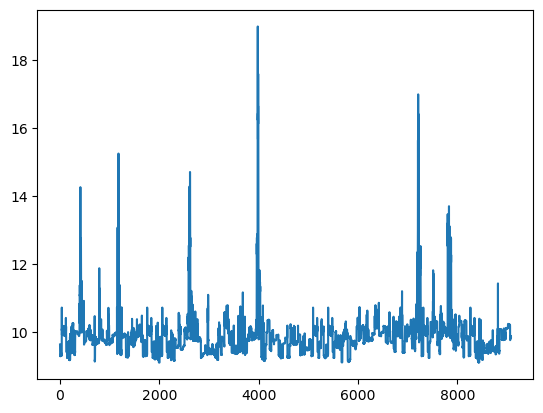

In [36]:
df_act.reset_index()['RESULTANT'].plot();

In [47]:
df_eat.columns

Index(['ACTIVITY', 'X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Z0', 'Z1',
       'Z2', 'Z3', 'Z4', 'Z5', 'Z6', 'Z7', 'Z8', 'Z9', 'XAVG', 'YAVG', 'ZAVG',
       'XPEAK', 'YPEAK', 'ZPEAK', 'XABSOLDEV', 'YABSOLDEV', 'ZABSOLDEV',
       'XSTANDDEV', 'YSTANDDEV', 'ZSTANDDEV', 'XVAR', 'YVAR', 'ZVAR', 'XMFCC0',
       'XMFCC1', 'XMFCC2', 'XMFCC3', 'XMFCC4', 'XMFCC5', 'XMFCC6', 'XMFCC7',
       'XMFCC8', 'XMFCC9', 'XMFCC10', 'XMFCC11', 'XMFCC12', 'YMFCC0', 'YMFCC1',
       'YMFCC2', 'YMFCC3', 'YMFCC4', 'YMFCC5', 'YMFCC6', 'YMFCC7', 'YMFCC8',
       'YMFCC9', 'YMFCC10', 'YMFCC11', 'YMFCC12', 'ZMFCC0', 'ZMFCC1', 'ZMFCC2',
       'ZMFCC3', 'ZMFCC4', 'ZMFCC5', 'ZMFCC6', 'ZMFCC7', 'ZMFCC8', 'ZMFCC9',
       'ZMFCC10', 'ZMFCC11', 'ZMFCC12', 'XYCOS', 'XZCOS', 'YZCOS', 'XYCOR',
       'XZCOR', 'YZCOR', 'RESULTANT', 'ID'],
      dtype='object')

In [61]:
df_eat["ACTIVITY"].unique()

array(['H', 'I', 'J', 'K', 'L'], dtype=object)

## Multivariate A-R Model

We can treat the learned characteristics of all the timeseries data observed to-date, as well as the other covariates observed at the same time step, as informative about the structure of the unrealised current state of the predictor. 


In [123]:
df_eat_lim = df_eat[["ID", "ACTIVITY", "ZSTANDDEV", "RESULTANT"]]
df_eat_lim["ZSTANDDEV_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
df_eat_lim["RESULTANT_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(1)
df_eat_lim["ZPEAK_avg"] = [avg_peak.loc[("Eat_avg", i), "ZPEAK"] for i in df_eat_lim["ID"]]
df_eat_lim["ZSTANDDEV_avg"] = [avg_peak.loc[("Eat_avg", i), "ZSTANDDEV"] for i in df_eat_lim["ID"]]
df_eat_lim["RESULTANT_avg"] = [avg_peak.loc[("Eat_avg", i), "RESULTANT"] for i in df_eat_lim["ID"]]
df_eat_lim["ENTROPY_avg"] = [entropy.loc[("eat_entr_mean", i), 0] for i in df_eat_lim["ID"]]
df_eat_lim = df_eat_lim.dropna()

id_indx, unique_ids = pd.factorize(df_eat_lim["ID"])
act_indx, unique_acts = pd.factorize(df_eat_lim["ACTIVITY"])
coords = {"ids": unique_ids, "acts": unique_acts, "obs": range(len(df_eat_lim["RESULTANT"]))}

/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_865/220758288.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_eat_lim["ZSTANDDEV_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_865/220758288.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_eat_lim["RESULTANT_lag1"] = df_eat_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(1)
/var/folders/_9/ybs93hbd4m31tcwj1dzss_c40000gr/T/ipykernel_865/220758288.py:4:

In [125]:
with pm.Model(coords=coords) as model:
    res_lag1_data = pm.MutableData("res_lag1_data", df_eat_lim["RESULTANT_lag1"].values)
    zstanddev_data = pm.MutableData("zstanddev_data", df_eat_lim["ZSTANDDEV"].values)
    zstanddev_lag1_data = pm.MutableData("zstanddev_lag1_data", df_eat_lim["ZSTANDDEV_lag1"].values)
    zpeak_avg_data = pm.MutableData("zpeak_avg_data", df_eat_lim["ZPEAK_avg"].values)
    zstanddev_avg_data = pm.MutableData("zstanddev_avg_data", df_eat_lim["ZSTANDDEV_avg"].values)
    resultant_avg_data = pm.MutableData("resultant_avg_data", df_eat_lim["RESULTANT_avg"].values)
    entropy_avg_data = pm.MutableData("entropy_avg_data", df_eat_lim["ENTROPY_avg"].values)

    ## Level 1
    global_intercept = pm.Normal("global_intercept", 10, 2)
    global_sigma = pm.HalfStudentT("global_sigma", 1, 3)
    
    global_zpeak_avg_beta = pm.Normal("global_zpeak_avg_beta", 0, 1)
    global_zstanddev_avg_beta = pm.Normal("global_zstanddev_avg_beta", 0, 1)
    global_resultant_avg_beta = pm.Normal("global_resultant_avg_beta", 0, 1)
    global_entropy_avg_beta = pm.Normal("global_entropy_avg_beta", 0, 1)
    
    global_res_lag1_beta = pm.Normal("global_res_lag1_beta", 0, 1)
    global_zstanddev_beta = pm.Normal("global_zstanddev_beta", 0, 1)
    global_zstanddev_lag1_beta = pm.Normal("global_zstanddev_lag1_beta", 0, 1)

    subject_intercept_sigma = pm.HalfNormal("subject_intercept_sigma", 2)
    activity_intercept_sigma = pm.HalfNormal("activity_intercept_sigma", 2)

    ## Level 2
    subject_intercept = pm.Normal("subject_intercept", 0, subject_intercept_sigma, dims="ids")
    activity_intercept = pm.Normal("activity_intercept", 0, activity_intercept_sigma, dims="acts")

    growth_model = pm.Deterministic(
        "growth_model",
        (global_intercept + subject_intercept[id_indx] + activity_intercept[act_indx])
        + global_zpeak_avg_beta * zpeak_avg_data
        + global_zstanddev_avg_beta * zstanddev_avg_data
        + global_resultant_avg_beta * resultant_avg_data
        + global_entropy_avg_beta * entropy_avg_data
        + global_res_lag1_beta * res_lag1_data
        + global_zstanddev_beta * zstanddev_data
        + global_zstanddev_lag1_beta * zstanddev_lag1_data,
    )
    
    outcome = pm.Normal(
        "outcome", growth_model, global_sigma, observed=df_eat_lim["RESULTANT"].values, dims="obs"
    )
    
    # idata_model = pm.sample_prior_predictive()
    # idata_model.extend(
    #     pm.sample(random_seed=100, target_accept=0.95, idata_kwargs={"log_likelihood": True})
    # )
    # idata_model.extend(pm.sample_posterior_predictive(idata_model))

Sampling: [activity_intercept, activity_intercept_sigma, global_entropy_avg_beta, global_intercept, global_res_lag1_beta, global_resultant_avg_beta, global_sigma, global_zpeak_avg_beta, global_zstanddev_avg_beta, global_zstanddev_beta, global_zstanddev_lag1_beta, outcome, subject_intercept, subject_intercept_sigma]
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [global_intercept, global_sigma, global_zpeak_avg_beta, global_zstanddev_avg_beta, global_resultant_avg_beta, global_entropy_avg_beta, global_res_lag1_beta, global_zstanddev_beta, global_zstanddev_lag1_beta, subject_intercept_sigma, activity_intercept_sigma, subject_intercept, activity_intercept]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2007 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Sampling: [outcome]


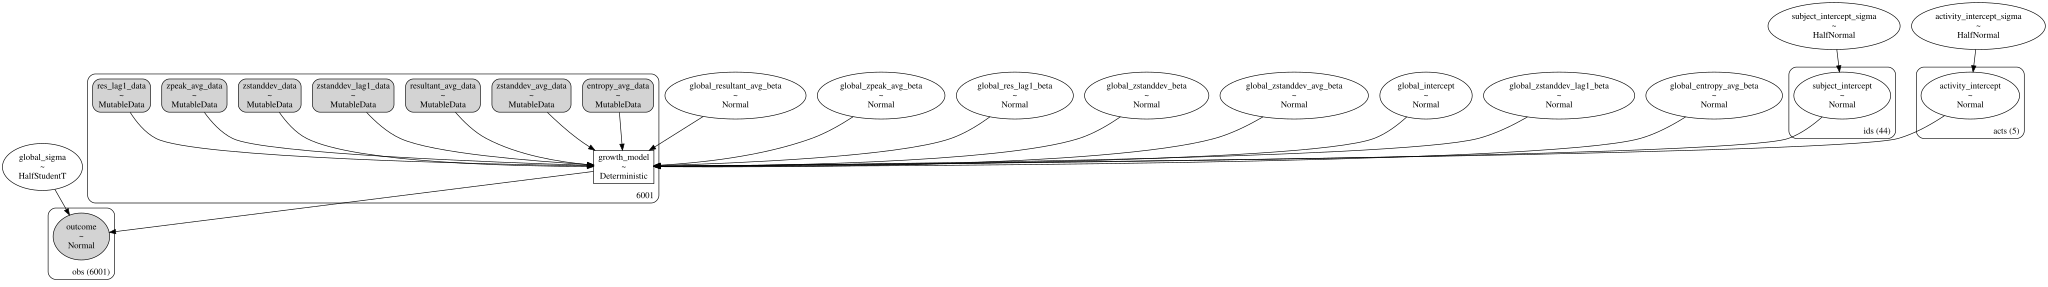

In [126]:
pm.model_to_graphviz(model)

In [128]:
idata_model

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

In [60]:
idata_model.posterior_predictive.outcome

NameError: name 'idata_model' is not defined

In [129]:
az.plot_trace(idata_model, figsize=(10, 6), kind="rank_vlines");

KeyboardInterrupt: 

Error in callback <function flush_figures at 0x143577c40> (for post_execute):


KeyboardInterrupt: 

In [130]:
az.summary(idata_model)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
global_intercept,-0.043,0.028,-0.096,0.010,0.000,0.000,3502.0,2587.0,1.00
global_zpeak_avg_beta,-0.000,0.000,-0.000,0.000,0.000,0.000,3774.0,2596.0,1.00
global_zstanddev_avg_beta,-0.178,0.089,-0.344,-0.010,0.003,0.002,1114.0,1613.0,1.00
global_resultant_avg_beta,0.110,0.006,0.100,0.122,0.000,0.000,212.0,728.0,1.02
global_entropy_avg_beta,-0.008,0.019,-0.045,0.026,0.000,0.000,1660.0,2062.0,1.00
...,...,...,...,...,...,...,...,...,...
growth_model[5996],10.045,0.003,10.040,10.051,0.000,0.000,705.0,1902.0,1.00
growth_model[5997],10.040,0.003,10.035,10.046,0.000,0.000,691.0,1871.0,1.00
growth_model[5998],10.046,0.003,10.041,10.052,0.000,0.000,712.0,1981.0,1.00
growth_model[5999],10.044,0.003,10.038,10.049,0.000,0.000,695.0,1929.0,1.00


In [147]:
print(df_eat_lim.loc[df_eat_lim["ID"] == 1601, :])

for i in df_eat_lim["ID"].unique():
    id_df = df_eat_lim.loc[df_eat_lim["ID"] == i, :]
    for a in id_df["ACTIVITY"].unique():
        plot_df = id_df.loc[id_df["ACTIVITY"] == a, :]
        if i == 1601:
            print(plot_df.shape)
            # print(np.where(df_eat_lim["ID"] == i and df_eat_lim["ACTIVITY"]) == a)

         ID ACTIVITY  ZSTANDDEV  RESULTANT  ZSTANDDEV_lag1  RESULTANT_lag1  \
class                                                                        
1601   1601        H   0.012512    9.70987        0.024936         9.65439   
1601   1601        H   0.002401    9.69924        0.012512         9.70987   
1601   1601        H   0.002494    9.70007        0.002401         9.69924   
1601   1601        H   0.006358    9.70012        0.002494         9.70007   
1601   1601        H   0.001841    9.68740        0.006358         9.70012   
...     ...      ...        ...        ...             ...             ...   
1601   1601        L   0.003105    9.58083        0.004350         9.57913   
1601   1601        L   0.002178    9.58791        0.003105         9.58083   
1601   1601        L   0.002954    9.58337        0.002178         9.58791   
1601   1601        L   0.004183    9.58841        0.002954         9.58337   
1601   1601        L   0.002565    9.58550        0.004183      

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

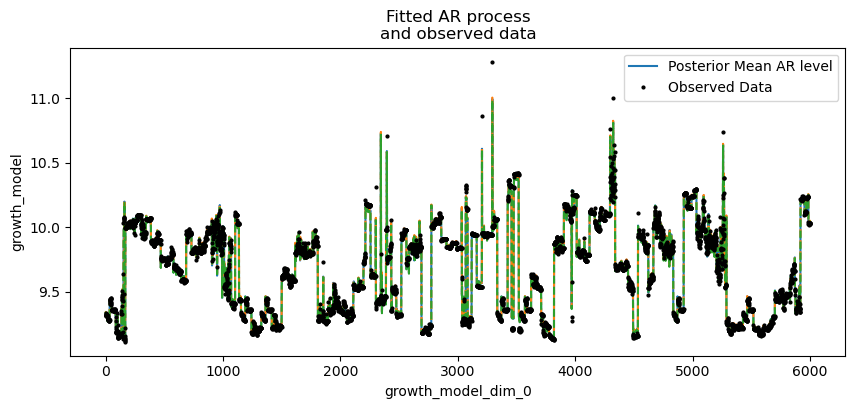

In [131]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_model.posterior.growth_model.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
(idata_model.posterior.growth_model.mean(["chain", "draw"]) + idata_model.posterior.growth_model.std(["chain", "draw"])).plot(ax=ax, ls = '--')
(idata_model.posterior.growth_model.mean(["chain", "draw"]) - idata_model.posterior.growth_model.std(["chain", "draw"])).plot(ax=ax, ls = '--')
ax.plot(df_eat_lim.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");

### Predictions

 - Forecast from the  posterior given the observations so far

In [ ]:
df_act_lim = df_act[["ID", "ACTIVITY", "ZSTANDDEV", "RESULTANT"]]
df_act_lim["ZSTANDDEV_lag1"] = df_act_lim.groupby(["ID", "ACTIVITY"])["ZSTANDDEV"].shift(1)
df_act_lim["RESULTANT_lag1"] = df_act_lim.groupby(["ID", "ACTIVITY"])["RESULTANT"].shift(1)
df_act_lim["ZPEAK_avg"] = [avg_peak.loc[("Act_avg", i), "ZPEAK"] for i in df_act_lim["ID"]]
df_act_lim["ZSTANDDEV_avg"] = [avg_peak.loc[("Act_avg", i), "ZSTANDDEV"] for i in df_act_lim["ID"]]
df_act_lim["RESULTANT_avg"] = [avg_peak.loc[("Act_avg", i), "RESULTANT"] for i in df_act_lim["ID"]]
df_act_lim["ENTROPY_avg"] = [entropy.loc[("act_entr_mean", i), 0] for i in df_act_lim["ID"]]
df_act_lim = df_act_lim.dropna()

# id_indx, unique_ids = pd.factorize(df_act_lim["ID"])
# act_indx, unique_acts = pd.factorize(df_act_lim["ACTIVITY"])
# coords = {"ids": unique_ids, "acts": unique_acts, "obs": range(len(df_act_lim["RESULTANT"]))}

In [ ]:
prediction_length = 1500
n = prediction_length - val_df.shape[0]
obs = list(range(prediction_length))

with model:
    ## We need to have coords for the observations minus the lagged term to correctly centre the prediction step
    AR.add_coords({"obs_id_fut_1": range(df_act.RESULTANT.values.shape[0] - 1, prediction_length, 1)})
    AR.add_coords({"obs_id_fut": range(df_act.RESULTANT.values.shape[0], prediction_length, 1)})
    # condition on the learned values of the AR process
    # initialise the future AR process precisely at the last observed value in the AR process
    # using the special feature of the dirac delta distribution to be 0 everywhere else.
    ar1_fut = pm.AR(
        "ar1_fut",
        init_dist=pm.DiracDelta.dist(ar1[..., -1]),
        rho=coefs,
        sigma=sigma,
        constant=True,
        dims="obs_id_fut_1",
    )
    yhat_fut = pm.Normal("yhat_fut", mu=ar1_fut[1:], sigma=sigma, dims="obs_id_fut")
    # use the updated values and predict outcomes and probabilities:
    idata_preds = pm.sample_posterior_predictive(
        idata_ar, var_names=["likelihood", "yhat_fut"], predictions=True, random_seed=100
    )

In [ ]:
test_df = df_eat[["ACTIVITY", "ZSTANDDEV", "ZPEAK", "RESULTANT"]]
test_df["ZSTANDDEV_lag1"] = test_df.groupby(["ACTIVITY"])["ZSTANDDEV"].shift(1)
test_df["ZPEAK_lag1"] = test_df.groupby(["ACTIVITY"])["ZPEAK"].shift(1)
test_df["RESULTANT_lag1"] = test_df.groupby(["ACTIVITY"])["RESULTANT"].shift(1)
test_df = test_df.dropna()

id_indx, unique_ids = pd.factorize(test_df["ACTIVITY"])
coords = {"ids": unique_ids, "obs": range(len(test_df["RESULTANT"]))}
with pm.Model(coords=coords) as model:
    res_lag1_data = pm.MutableData("res_lag1_data", test_df["RESULTANT_lag1"].values)
    zpeak_data = pm.MutableData("zpeak_data", test_df["ZPEAK"].values)
    zpeak_lag1_data = pm.MutableData("zpeak_lag1_data", test_df["ZPEAK_lag1"].values)
    zstanddev_data = pm.MutableData("zstanddev_data", test_df["ZSTANDDEV"].values)
    zstanddev_lag1_data = pm.MutableData("zstanddev_lag1_data", test_df["ZSTANDDEV_lag1"].values)

    ## Level 1
    global_intercept = pm.Normal("global_intercept", 10, 2)
    global_sigma = pm.HalfStudentT("global_sigma", 1, 3)
    global_res_lag1_beta = pm.Normal("global_res_lag1_beta", 0, 1)
    global_zpeak_beta = pm.Normal("global_zpeak_beta", 0, 1)
    global_zpeak_lag1_beta = pm.Normal("global_zpeak_lag1_beta", 0, 1)
    global_zstanddev_beta = pm.Normal("global_zstanddev_beta", 0, 1)
    global_zstanddev_lag1_beta = pm.Normal("global_zstanddev_lag1_beta", 0, 1)

    subject_intercept_sigma = pm.HalfNormal("subject_intercept_sigma", 2)

    ## Level 2
    subject_intercept = pm.Normal("subject_intercept", 0, subject_intercept_sigma, dims="ids")

    growth_model = pm.Deterministic(
        "growth_model",
        (global_intercept + subject_intercept[id_indx])
        + global_res_lag1_beta * res_lag1_data
        + global_zpeak_beta * zpeak_data
        + global_zpeak_lag1_beta * zpeak_lag1_data
        + global_zstanddev_beta * zstanddev_data
        + global_zstanddev_lag1_beta * zstanddev_lag1_data,
    )
    
    outcome = pm.Normal(
        "outcome", growth_model, global_sigma, observed=test_df["RESULTANT"].values, dims="obs"
    )
    
    idata_m2 = pm.sample_prior_predictive()
    idata_m2.extend(
        pm.sample(random_seed=100, target_accept=0.95, idata_kwargs={"log_likelihood": True})
    )
    idata_m2.extend(pm.sample_posterior_predictive(idata_m2))

In [ ]:
pm.model_to_graphviz(AR)